# Dự đoán giá nhà bằng Gradient Boosting Regressor

Thí nghiệm xem việc kết hợp chất lượng nhà với diện tích sinh hoạt có giúp dự đoán giá tốt hơn hay không. Mô hình cơ sở dùng tham số mặc định, sau đó lần lượt thử đặc trưng tương tác và tinh chỉnh số cây, tốc độ học, độ sâu.

## 1. Đọc dữ liệu và chia tập

File `split_seed7.csv` chia dữ liệu thành 1.168 căn development và 292 căn holdout. Năm fold có sẵn trên development giúp các lượt chạy dùng cùng tập validation. Mô hình học `log(SalePrice)` và được chọn theo RMSE log trung bình. Holdout được dùng sau khi chốt cấu hình để tính RMSE log và MAE trên giá gốc.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, PredefinedSplit, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

cwd = Path.cwd()
root = next((p for p in (cwd, *cwd.parents) if (p / "data/raw/train.csv").is_file()), None)
if root is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục Challenge1 hoặc một thư mục con.")

raw = root / "data/raw"
train = pd.read_csv(raw / "train.csv")
test = pd.read_csv(raw / "test.csv")
split = pd.read_csv(root / "data/splits/split_seed7.csv")

data = train.merge(split, on="Id", validate="one_to_one")
dev = data.loc[data["split"].eq("development")].copy()
holdout = data.loc[data["split"].eq("holdout")].copy()
assert len(dev) + len(holdout) == len(train) == len(split)
assert set(dev["cv_fold"]) == set(range(5))

features = test.columns.drop("Id")
y_dev = np.log(dev["SalePrice"])
cv = PredefinedSplit(dev["cv_fold"].to_numpy())
print(f"Development: {len(dev)} | Holdout: {len(holdout)} | Test: {len(test)}")
display(dev.groupby("cv_fold").size().rename("Số căn validation"))

Development: 1168 | Holdout: 292 | Test: 1459


cv_fold
0    234
1    234
2    234
3    233
4    233
Name: Số căn validation, dtype: int64

## 2. Khám phá dữ liệu

Phần này dùng tập development để xem cột nào thiếu nhiều, giá nhà phân bố ra sao và giá thay đổi thế nào theo chất lượng tổng thể (`OverallQual`) và diện tích sinh hoạt (`GrLivArea`).

PoolQC          1163
MiscFeature     1131
Alley           1095
Fence            944
MasVnrType       687
FireplaceQu      544
LotFrontage      206
GarageCond        70
GarageType        70
GarageYrBlt       70
GarageQual        70
GarageFinish      70
BsmtFinType2      33
BsmtFinType1      32
BsmtExposure      32
dtype: int64

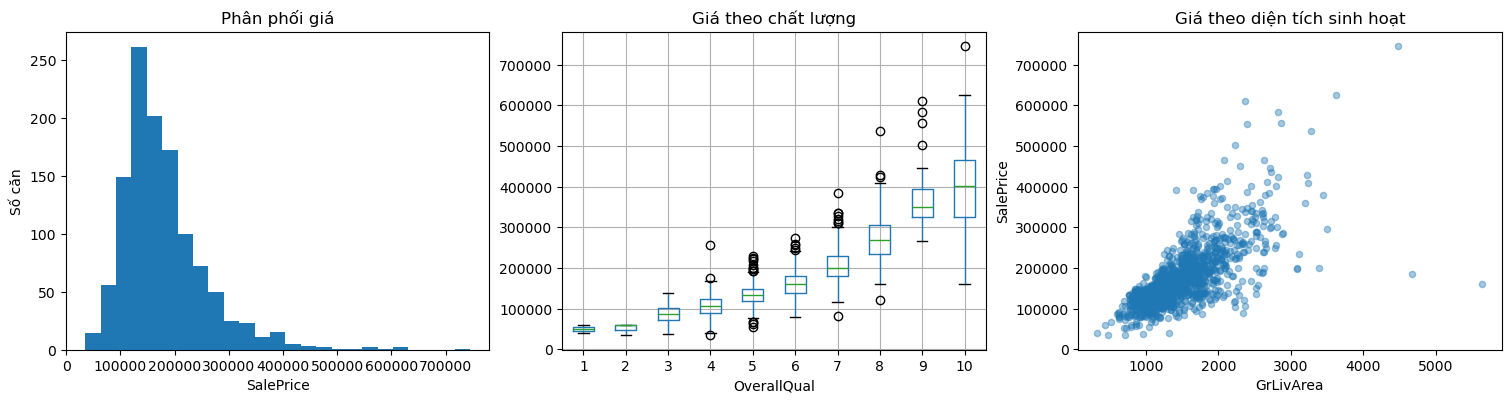

In [2]:
display(dev[features].isna().sum().sort_values(ascending=False).head(15))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
axes[0].hist(dev["SalePrice"], bins=25)
axes[0].set(title="Phân phối giá", xlabel="SalePrice", ylabel="Số căn")
dev.boxplot(column="SalePrice", by="OverallQual", ax=axes[1])
axes[1].set_title("Giá theo chất lượng")
dev.plot.scatter(x="GrLivArea", y="SalePrice", ax=axes[2], alpha=0.4)
axes[2].set_title("Giá theo diện tích sinh hoạt")
fig.suptitle("")
plt.show()

### Nhận xét từ biểu đồ

- `PoolQC`, `MiscFeature` và `Alley` thiếu nhiều nhất, lần lượt ở 1.163, 1.131 và 1.095 căn. Theo mô tả dữ liệu, NA ở `PoolQC` nghĩa là không có hồ bơi, còn NA ở `Alley` nghĩa là nhà không có lối vào qua hẻm.
- Phân phối giá lệch phải. Giá trung vị là 163,000, thấp hơn giá trung bình 179,879. Một số căn có giá cao kéo dài đuôi phân phối.
- Giá nhìn chung tăng theo chất lượng và diện tích. Tương quan Pearson với giá lần lượt là 0.79 và 0.70. Các căn có diện tích tương tự vẫn có thể chênh giá đáng kể, nên thí nghiệm tiếp theo kiểm tra xem tích của hai biến có giúp dự đoán tốt hơn không.
- **Điểm ngoại lệ trên biểu đồ diện tích và giá:** Căn có `Id=1299` có diện tích sinh hoạt lớn nhất trong tập development (5.642 ft²) nhưng bán với giá 160.000. Căn `Id=1183` có diện tích nhỏ hơn (4.476 ft²) và bán với giá 745.000. Hai điểm này cho thấy chỉ dựa vào diện tích sẽ khó giải thích chênh lệch giá. Cả hai căn được giữ trong dữ liệu huấn luyện.

## 3. Tiền xử lý và mô hình cơ sở

Biến số thiếu được điền bằng trung vị. Với các biến phân loại, những trường hợp NA có nghĩa là không có hạng mục được gán nhãn `None`. Riêng `MasVnrType` được gán `None` khi loại vật liệu bị thiếu và diện tích ốp bằng 0. Các giá trị thiếu còn lại trong biến phân loại được điền bằng giá trị phổ biến nhất, rồi mã hóa one-hot.

Pipeline học cách điền thiếu và mã hóa từ phần huấn luyện của từng fold. Mô hình cơ sở dùng các siêu tham số mặc định của Gradient Boosting và đặt `random_state=7`.

In [3]:
absence_columns = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
    "BsmtFinType2", "FireplaceQu", "GarageType", "GarageFinish",
    "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature",
]

def make_features(frame, use_interaction=False):
    X = frame[features].copy()
    no_veneer = X["MasVnrType"].isna() & X["MasVnrArea"].eq(0)
    X.loc[no_veneer, "MasVnrType"] = "None"
    if use_interaction:
        X["QualityArea"] = X["OverallQual"] * X["GrLivArea"]
    return X

X_dev = make_features(dev)
other_categorical = X_dev.select_dtypes(exclude="number").columns.difference(absence_columns)

def categorical_pipeline(strategy, fill_value=None):
    return Pipeline([
        ("impute", SimpleImputer(strategy=strategy, fill_value=fill_value)),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ])

preprocess = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), make_column_selector(dtype_include=np.number)),
    ("absence", categorical_pipeline("constant", "None"), absence_columns),
    ("categorical", categorical_pipeline("most_frequent"), other_categorical),
])
baseline = Pipeline([
    ("preprocess", preprocess),
    ("model", GradientBoostingRegressor(random_state=7)),
])

metric = "neg_root_mean_squared_error"

def summarize(name, validation, training, seconds):
    return {
        "Lượt": name,
        "CV RMSE log": np.mean(validation),
        "Độ lệch chuẩn": np.std(validation),
        "Train RMSE log": np.mean(training),
        "Thời gian (giây)": seconds,
        **{f"Fold {i}": score for i, score in enumerate(validation)},
    }

def evaluate(name, X):
    start = perf_counter()
    scores = cross_validate(
        baseline, X, y_dev, cv=cv, scoring=metric,
        return_train_score=True, error_score="raise",
    )
    return summarize(name, -scores["test_score"], -scores["train_score"], perf_counter() - start)

base_result = evaluate("Mai-01 Baseline", X_dev)
display(pd.DataFrame([base_result]).round(5))

,Lượt,CV RMSE log,Độ lệch chuẩn,Train RMSE log,Thời gian (giây),Fold 0,Fold 1,Fold 2,Fold 3,Fold 4
0,Mai-01 Baseline,0.13655,0.01619,0.07096,4.02265,0.1429,0.12331,0.16433,0.13334,0.11887


## 4. Thử đặc trưng tương tác

Đặc trưng `QualityArea` là tích của `OverallQual` và `GrLivArea`. Bước này chỉ thêm một cột và giữ nguyên siêu tham số để xem thay đổi đến từ đặc trưng mới. Bộ đặc trưng có RMSE log validation thấp hơn được dùng cho bước tinh chỉnh.

In [4]:
X_interaction = make_features(dev, use_interaction=True)
interaction_result = evaluate("Mai-02 QualityArea", X_interaction)
use_interaction = interaction_result["CV RMSE log"] < base_result["CV RMSE log"]
X_selected = X_interaction if use_interaction else X_dev

display(pd.DataFrame([base_result, interaction_result]).round(5))
print("Dùng QualityArea cho lượt tinh chỉnh:", use_interaction)

,Lượt,CV RMSE log,Độ lệch chuẩn,Train RMSE log,Thời gian (giây),Fold 0,Fold 1,Fold 2,Fold 3,Fold 4
0,Mai-01 Baseline,0.13655,0.01619,0.07096,4.02265,0.14290,0.12331,0.16433,0.13334,0.11887
1,Mai-02 QualityArea,0.13067,0.01421,0.07083,3.97807,0.13487,0.12069,0.15346,0.13284,0.11150


Dùng QualityArea cho lượt tinh chỉnh: True


## 5. Tinh chỉnh siêu tham số

Thử 12 cấu hình trên cùng 5 fold bằng cách thay đổi `learning_rate`, `n_estimators` và `max_depth`. Cấu hình có RMSE log validation trung bình thấp nhất được chọn. Điểm train được ghi thêm để xem mô hình khớp dữ liệu đã học đến mức nào.

In [5]:
search = GridSearchCV(
    baseline,
    {
        "model__learning_rate": [0.03, 0.05, 0.10],
        "model__n_estimators": [100, 200],
        "model__max_depth": [2, 3],
    },
    cv=cv, scoring=metric, return_train_score=True, error_score="raise",
)
start = perf_counter()
search.fit(X_selected, y_dev)
elapsed = perf_counter() - start
i = search.best_index_
results = search.cv_results_
folds = range(cv.get_n_splits())
tuned_result = summarize(
    "Mai-03 Tinh chỉnh",
    [-results[f"split{fold}_test_score"][i] for fold in folds],
    [-results[f"split{fold}_train_score"][i] for fold in folds],
    elapsed,
)

display(pd.DataFrame([base_result, interaction_result, tuned_result]).round(5))
grid_scores = pd.DataFrame({
    "Tham số": results["params"],
    "CV RMSE log": -results["mean_test_score"],
    "Train RMSE log": -results["mean_train_score"],
})
display(grid_scores.sort_values("CV RMSE log").round(5))
print("Tham số được chọn:", search.best_params_)

,Lượt,CV RMSE log,Độ lệch chuẩn,Train RMSE log,Thời gian (giây),Fold 0,Fold 1,Fold 2,Fold 3,Fold 4
0,Mai-01 Baseline,0.13655,0.01619,0.07096,4.02265,0.14290,0.12331,0.16433,0.13334,0.11887
1,Mai-02 QualityArea,0.13067,0.01421,0.07083,3.97807,0.13487,0.12069,0.15346,0.13284,0.11150
2,Mai-03 Tinh chỉnh,0.12863,0.01493,0.05189,60.08266,0.13460,0.11734,0.15211,0.13040,0.10871


,Tham số,CV RMSE log,Train RMSE log
11,"{'model__learning_rate': 0.1, 'model__max_dept...",0.12863,0.05189
10,"{'model__learning_rate': 0.1, 'model__max_dept...",0.13067,0.07083
9,"{'model__learning_rate': 0.1, 'model__max_dept...",0.13112,0.07834
7,"{'model__learning_rate': 0.05, 'model__max_dep...",0.13128,0.07023
3,"{'model__learning_rate': 0.03, 'model__max_dep...",0.13380,0.08397
5,"{'model__learning_rate': 0.05, 'model__max_dep...",0.13433,0.09486
8,"{'model__learning_rate': 0.1, 'model__max_dept...",0.13467,0.09500
6,"{'model__learning_rate': 0.05, 'model__max_dep...",0.13773,0.09054
1,"{'model__learning_rate': 0.03, 'model__max_dep...",0.14299,0.11127
4,"{'model__learning_rate': 0.05, 'model__max_dep...",0.14737,0.11880


Tham số được chọn: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}


### Kết quả cross-validation

Thêm `QualityArea` giúp RMSE log trung bình giảm từ **0.13655** xuống **0.13067**. Điểm cải thiện ở cả 5 fold, nên đặc trưng này được giữ lại để tinh chỉnh.

Cấu hình tốt nhất dùng 200 cây, `learning_rate=0.1` và `max_depth=3`, đạt **0.12863 ± 0.01493** trên validation. RMSE log trên train là **0.05189**. Sai số train thấp hơn nhiều, cho thấy mô hình khớp dữ liệu đã học khá sát. Mức cải thiện trên validation so với trước khi tinh chỉnh là **0.00204**.

## 6. Đánh giá holdout và phân tích sai số

Cấu hình đã chọn được đánh giá trên 292 căn holdout. Phần dư bằng giá thực tế trừ giá dự đoán. Phần dư dương nghĩa là mô hình dự đoán thấp hơn giá thực tế.

Holdout RMSE log: 0.11589 | MAE giá: 15,236


,Id,OverallQual,GrLivArea,SalePrice,PredictedSalePrice,Residual,AbsoluteError
691,692,10,4316,755000,527495.0,227505.0,227505.0
1324,1325,8,1795,147000,280658.0,-133658.0,133658.0
313,314,7,2036,375000,271829.0,103171.0,103171.0
185,186,10,3608,475000,395520.0,79480.0,79480.0
451,452,7,1533,280000,214475.0,65525.0,65525.0


SalePrice
(54999.999, 129000.0]    10569.0
(129000.0, 162450.0]     10411.0
(162450.0, 224600.0]     13575.0
(224600.0, 755000.0]     26386.0
Name: AbsoluteError, dtype: float64

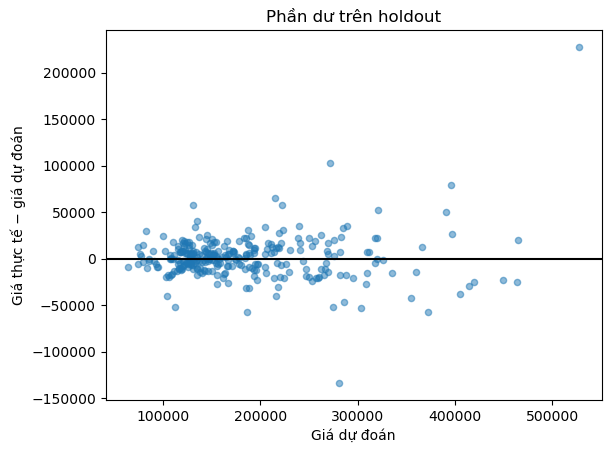

In [6]:
hold_log = search.best_estimator_.predict(make_features(holdout, use_interaction))
hold_price = np.exp(hold_log)
actual = holdout["SalePrice"]
hold_rmse = np.sqrt(mean_squared_error(np.log(actual), hold_log))
hold_mae = mean_absolute_error(actual, hold_price)
print(f"Holdout RMSE log: {hold_rmse:.5f} | MAE giá: {hold_mae:,.0f}")

errors = holdout[["Id", "OverallQual", "GrLivArea", "SalePrice"]].copy()
errors["PredictedSalePrice"] = hold_price
errors["Residual"] = actual - hold_price
errors["AbsoluteError"] = errors["Residual"].abs()
display(errors.nlargest(5, "AbsoluteError").round(0))

price_groups = pd.qcut(actual, 4, duplicates="drop")
display(errors.groupby(price_groups, observed=True)["AbsoluteError"].mean().round(0))
ax = errors.plot.scatter(x="PredictedSalePrice", y="Residual", alpha=0.5)
ax.axhline(0, color="black")
ax.set(title="Phần dư trên holdout", xlabel="Giá dự đoán", ylabel="Giá thực tế − giá dự đoán")
plt.show()

### Kết quả holdout

RMSE log là **0.11589** và MAE trên giá gốc là **15.236**. Nhóm nhà có giá trên 224.600 có MAE cao nhất (**26.386**), trong khi ba nhóm giá còn lại có MAE từ 10.411 đến 13.575.

Trong 5 căn có sai số tuyệt đối lớn nhất, 4 căn bị dự đoán thấp hơn giá thực tế. Căn sai lệch nhiều nhất có chất lượng 10, diện tích sinh hoạt 4.316 và giá bán 755.000. Mô hình dự đoán 527.495, thấp hơn thực tế 227.505. Căn có `Id=1325` lệch theo hướng ngược lại, với giá dự đoán cao hơn thực tế 133.658.

## 7. Xuất submission và dự đoán ngoài fold

Sau khi đánh giá holdout, mô hình được huấn luyện lại trên toàn bộ tập train. Hàm `exp()` đưa dự đoán về giá gốc. File submission có 1.459 dòng theo thứ tự `Id` của file mẫu.

File OOF có 1.168 dự đoán trên development. Mỗi căn được dự đoán bởi mô hình học từ bốn fold còn lại. Nhóm có thể ghép OOF theo `Id` để thử kết hợp mô hình. Chạy lại ô này sẽ cập nhật hai file dự đoán.

In [7]:
final_model = clone(search.best_estimator_)
final_model.fit(make_features(train, use_interaction), np.log(train["SalePrice"]))
test_prices = pd.Series(
    np.exp(final_model.predict(make_features(test, use_interaction))),
    index=test["Id"],
)

submission = pd.read_csv(raw / "sample_submission.csv")
assert submission["Id"].is_unique and test_prices.index.is_unique
assert set(submission["Id"]) == set(test_prices.index)
submission["SalePrice"] = submission["Id"].map(test_prices)
assert np.isfinite(submission["SalePrice"]).all() and submission["SalePrice"].gt(0).all()

oof_log = cross_val_predict(clone(final_model), X_selected, y_dev, cv=cv)
oof = dev[["Id", "cv_fold", "SalePrice"]].copy()
oof["PredictedSalePrice"] = np.exp(oof_log)

for relative_path, frame in [
    ("results/submissions/submission_Mai.csv", submission),
    ("members/Mai/outputs/predictions/oof_Mai.csv", oof),
]:
    output = root / relative_path
    output.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(output, index=False)
    print(f"{relative_path}: {len(frame)} dòng")

display(submission.head())

results/submissions/submission_Mai.csv: 1459 dòng
members/Mai/outputs/predictions/oof_Mai.csv: 1168 dòng


,Id,SalePrice
0,1461,123252.398482
1,1462,158191.095113
2,1463,177363.491922
3,1464,193059.320344
4,1465,186450.459398


## 8. Kết luận

Thêm tương tác chất lượng và diện tích giúp giảm RMSE log CV từ **0.13655** xuống **0.13067**. Tinh chỉnh siêu tham số giảm tiếp xuống **0.12863**. Trên holdout, nhóm giá cao nhất có MAE lớn nhất. Kết quả này cho thấy nên xem cả sai số trên giá gốc khi phân tích các căn giá cao.